# gainmat tier: trivalent lanthanide 4f^N spectroscopy
Determinant CI (F2,F4,F6, zeta, alpha, beta, gamma) -> J multiplets; U^(2,4,6) from the eigenvectors;
Judd-Ofelt radiative rates, branching ratios, tau_rad; energy-gap-law multiphonon rates.
Runs on CPU in a few minutes. Upload the `gainmat` folder (or `gainmat.zip`) to `/content` first.

In [1]:
%pip -q install numpy scipy sympy matplotlib
import os, sys, zipfile
ROOT = '/content' if os.path.isdir('/content') else os.path.abspath('..')
if os.path.exists(os.path.join(ROOT, 'gainmat.zip')) and not os.path.isdir(os.path.join(ROOT, 'gainmat')):
    zipfile.ZipFile(os.path.join(ROOT, 'gainmat.zip')).extractall(ROOT)
# accept either /content/gainmat/gainmat (project folder) or /content/gainmat (package)
for cand in [os.path.join(ROOT, 'gainmat'), ROOT]:
    if os.path.isdir(os.path.join(cand, 'gainmat', 'ln4f')):
        sys.path.insert(0, cand); break
OUT = os.environ.get('LN_OUT', '/content/results' if os.path.isdir('/content') else os.path.join(ROOT, 'results'))
os.makedirs(OUT, exist_ok=True)
import gainmat.ln4f as ln
print('gainmat.ln4f from', ln.__file__)

Note: you may need to restart the kernel to use updated packages.


gainmat.ln4f from /home/claude/gainmat/gainmat/ln4f/__init__.py


## Validation: levels, Nd:YAG, Er:silica vs Er:ZBLAN

In [2]:
from gainmat.ln4f.run_ln import validate, run_dopant, free_ion
val = validate(verbose=True)


Er3+ multiplets (LaF3 Carnall params)   calc   exp   diff
  4I15/2           0               
  4I13/2        6490    6500    -10
  4I11/2       10104   10150    -46
  4I9/2        12164   12400   -236
  4F9/2        14872   15250   -378
  4S3/2        18052   18400   -348
  2H11/2       18934   19150   -216
  4F7/2        19909   20450   -541
  4F5/2        21632   22150   -518
  4F3/2        21940   22500   -560
  2G9/2        24102   24550   -448
  4G11/2       25927   26350   -423
  4G9/2        26804               
  RMS (<25000 cm-1) = 380 cm-1 ; without beta/gamma = 809

Nd3+ multiplets (LaF3 Carnall params)   calc   exp   diff
  4I9/2            0               
  4I11/2        1879    2000   -121
  4I13/2        3881    3950    -69
  4I15/2        5963    5950     13
  4F3/2        11179   11550   -371
  4F5/2        12234   12550   -316
  2H9/2        12549   12650   -101
  4S3/2        13106   13500   -394
  4F7/2        13239   13450   -211
  4F9/2        14560   14750   -

### Why 2.7 um works in ZBLAN but not silica
The 4I11/2-4I13/2 gap (~3600 cm^-1) is ~3 silica phonons (1100 cm^-1) but ~6 ZBLAN phonons (~580 cm^-1).
The energy-gap law turns that into W_nr ~ 6e4 /s (silica) vs ~2e1 /s (ZBLAN), against A_rad ~ 100 /s.

In [3]:
import numpy as np
from gainmat.ln4f.nonrad import w_phonon_order
gap = 3610.0
for hw in [350, 500, 580, 700, 900, 1100, 1200]:
    print(f'hw_max={hw:5d} cm-1  p={gap/hw:4.1f}  W_nr(phonon-order)={w_phonon_order(gap, hw):9.3g} /s')
# host-agnostic usage, e.g. with the host tier's computed phonon cutoff:
er = run_dopant('Er3+', 'ZBLAN', phonon_max_cm1=580, nr_model='phonon')
print('Er:ZBLAN (phonon-order law) eta(4I11/2)=%.3f' % er.quantum_eff['4I11/2'])

hw_max=  350 cm-1  p=10.3  W_nr(phonon-order)=     1.12 /s
hw_max=  500 cm-1  p= 7.2  W_nr(phonon-order)=     29.5 /s
hw_max=  580 cm-1  p= 6.2  W_nr(phonon-order)=      108 /s
hw_max=  700 cm-1  p= 5.2  W_nr(phonon-order)=      567 /s
hw_max=  900 cm-1  p= 4.0  W_nr(phonon-order)= 5.86e+03 /s
hw_max= 1100 cm-1  p= 3.3  W_nr(phonon-order)= 4.56e+04 /s
hw_max= 1200 cm-1  p= 3.0  W_nr(phonon-order)=  1.2e+05 /s


Er:ZBLAN (phonon-order law) eta(4I11/2)=0.499


## Dieke-style diagram (free-ion multiplets with LaF3 parameters)

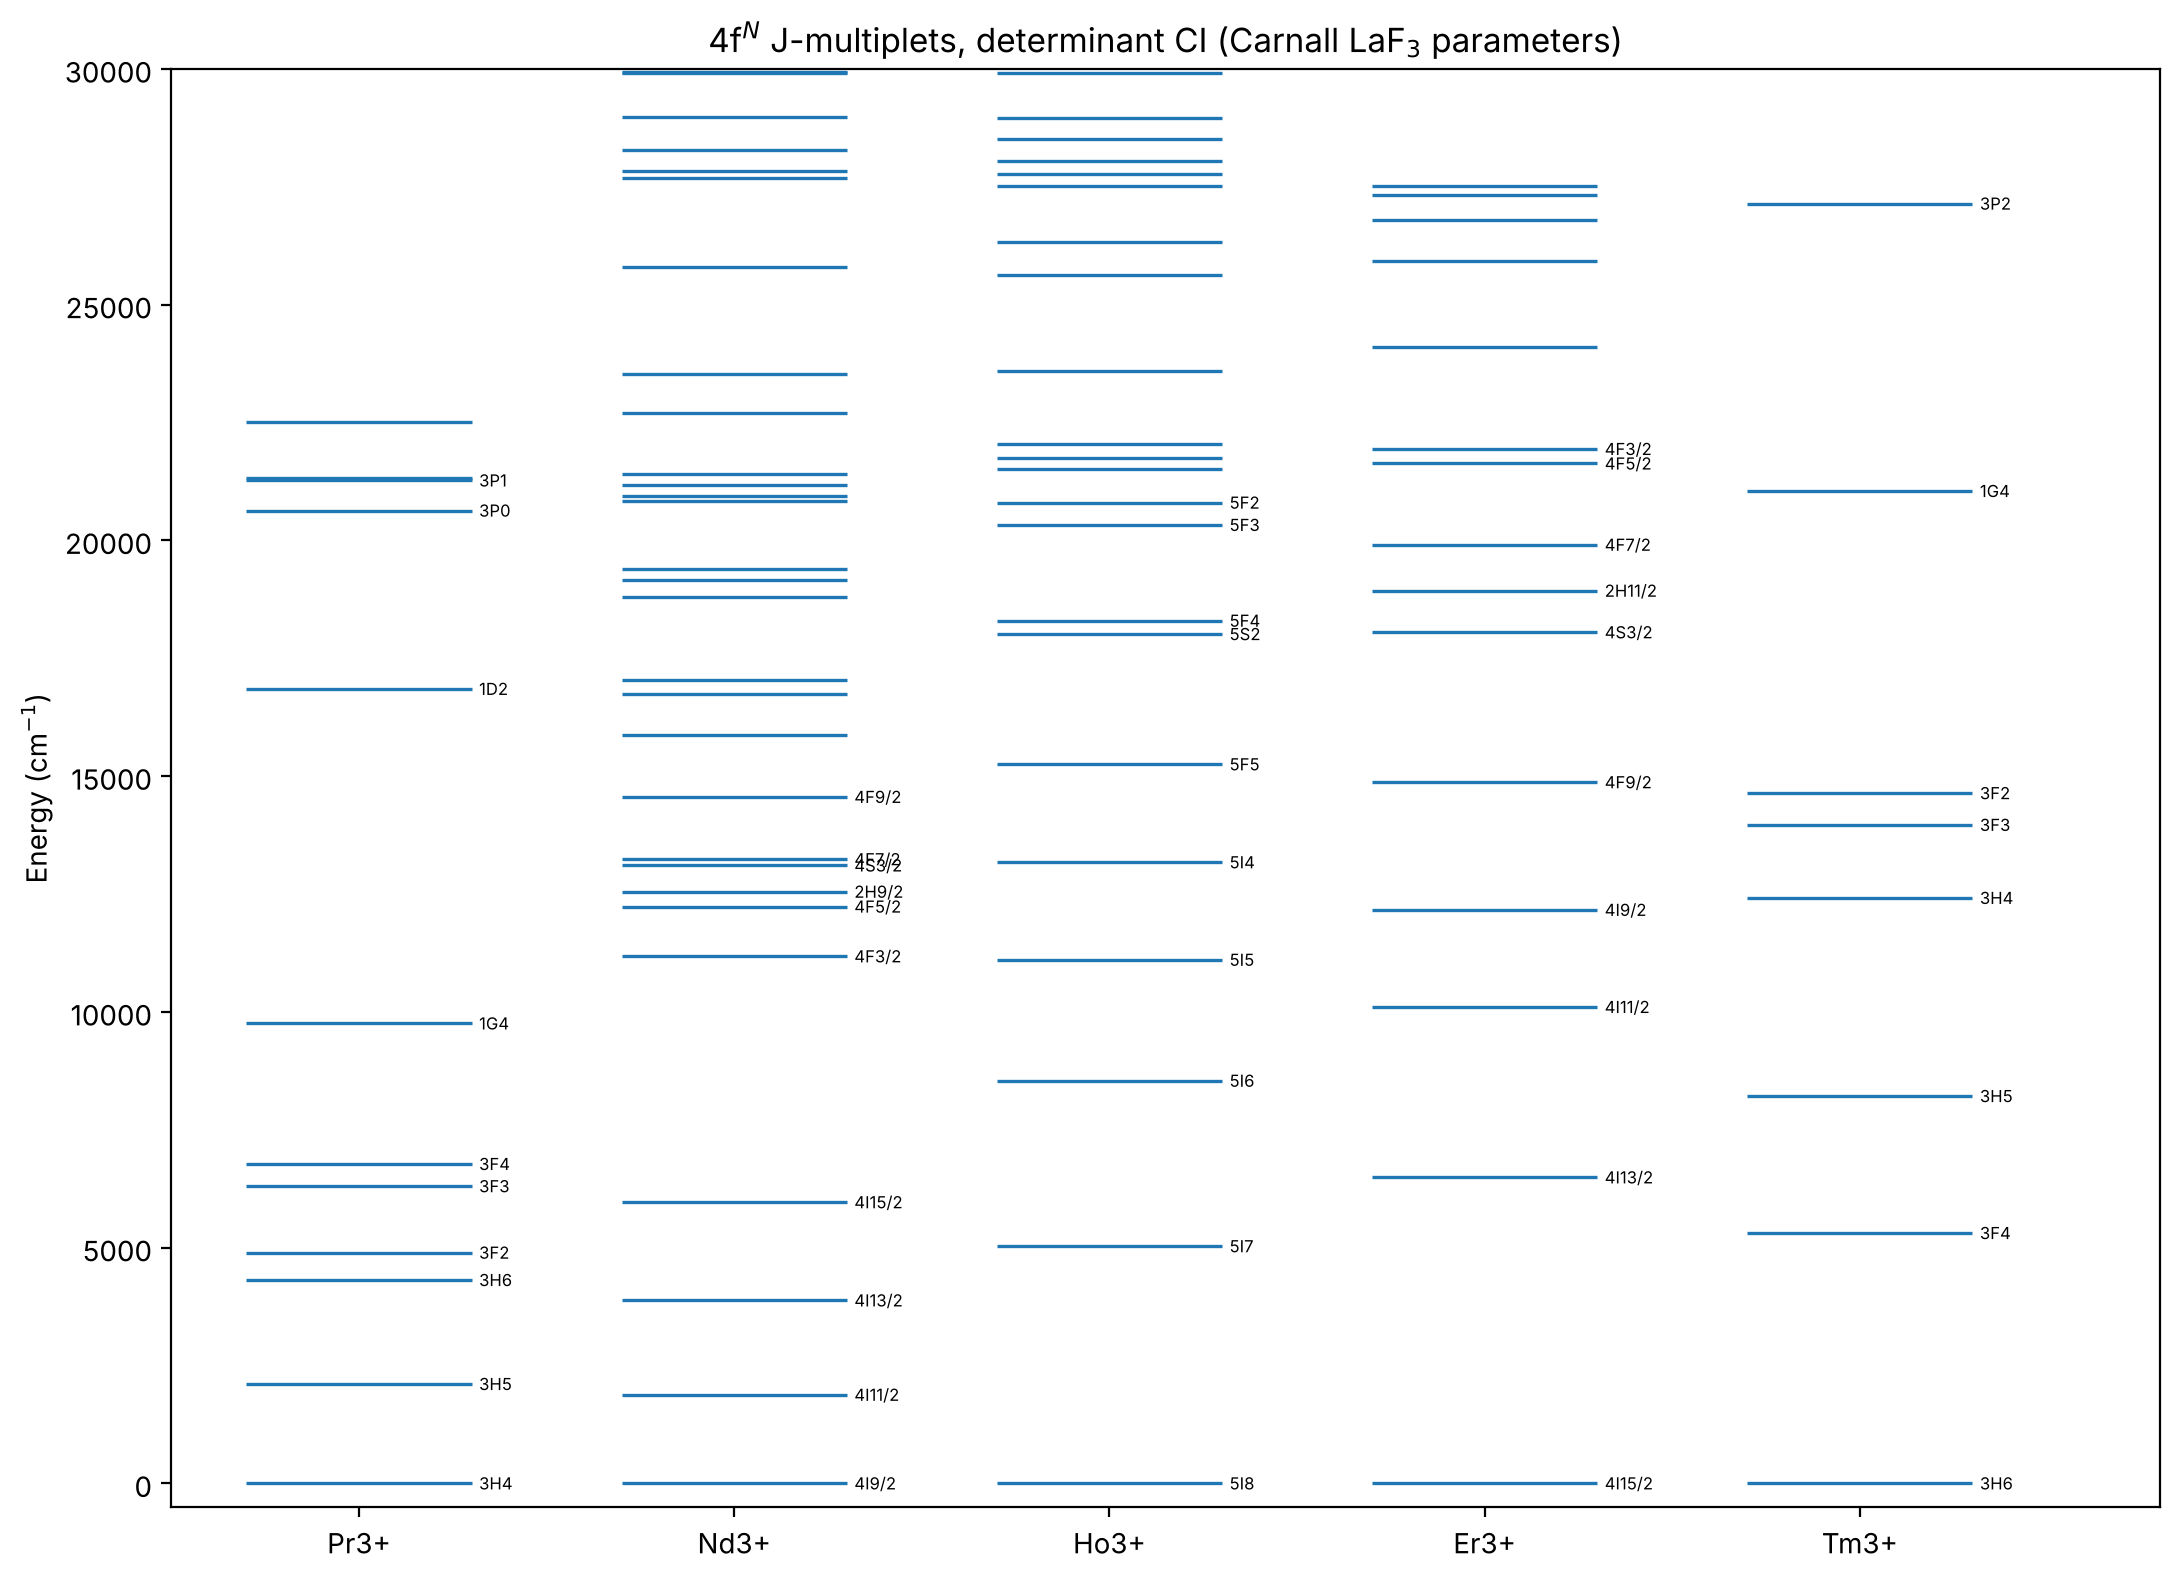

In [4]:
import matplotlib.pyplot as plt
ions = ['Pr3+', 'Nd3+', 'Ho3+', 'Er3+', 'Tm3+']
levels = {}
fig, ax = plt.subplots(figsize=(11, 8))
for k, ion in enumerate(ions):
    r = free_ion(ion)
    levels[ion] = [(m['label'], m['energy']) for m in r.multiplets if m['energy'] < 30000]
    for lab, e in levels[ion]:
        ax.hlines(e, k - 0.3, k + 0.3, lw=1.2, color='C0')
    for lab, e in levels[ion][:10]:
        ax.text(k + 0.32, e, lab, fontsize=6, va='center')
ax.set_xticks(range(len(ions))); ax.set_xticklabels(ions)
ax.set_ylabel('Energy (cm$^{-1}$)'); ax.set_ylim(-500, 30000); ax.set_xlim(-0.5, len(ions) - 0.2)
ax.set_title('4f$^N$ J-multiplets, determinant CI (Carnall LaF$_3$ parameters)')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'dieke_ln.png'), dpi=150); plt.show()

In [5]:
import json, dataclasses
res = dict(validation=val, levels=levels,
           dopants={f'{ion}:{h}': dataclasses.asdict(run_dopant(ion, h))
                    for ion, h in [('Nd3+', 'YAG'), ('Er3+', 'silica'), ('Er3+', 'ZBLAN'), ('Er3+', 'LiYF4')]})
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
with open(os.path.join(OUT, 'ln_results.json'), 'w') as f:
    json.dump(clean(res), f, indent=1, default=float)
print('saved', os.path.join(OUT, 'ln_results.json'))

saved /tmp/claude-0/-home-claude/2757f74d-0693-5139-8c2f-db604866db2f/scratchpad/results/ln_results.json
